##DAY1

###Foundations of Neural Network

##PyTorch setup

In [ ]:
#Run this at the START of every notebook this week
import torch
print(f"PyTorch version:  {torch.__version__}")
print(f"GPU available:  {torch.cuda.is_available()}")
device =  torch.device("cuda" if torch.cuda.is_available()  else "cpu")
print(f"Using device: {device}")

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


#A TENSOR is just a NumPy array that can also run on a GPU
# and automatically track gradients for us (we'll see this Day 2)

scalar = torch.tensor(3.14)
vector = torch.tensor([1.0,2.0,3.0])
matrix = torch.tensor([[1.0,2.0],[3.0,4.0]])

print(f"Scalar: {scalar}, shape: {scalar.shape}")
print(f"Vector: {vector}, shape: {vector.shape}")
print(f"Matrix:\n{matrix}\nshape: {matrix.shape}")

#Tensor Work almost exactly like Numpy arrays
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor ([4.0, 5.0, 6.0])
print(f"\na + b = {a + b}")
print(f"a * b = {a * b}")           #element wise
print(f"a @ b = {a @ b}")           #dot product (matrix)

#Random tensors (this is how a networks weights START -- Random!)
random_weights = torch.rand(3,4)
print(f"\nRandom 3x4 Weights Matrix:\n{random_weights}")

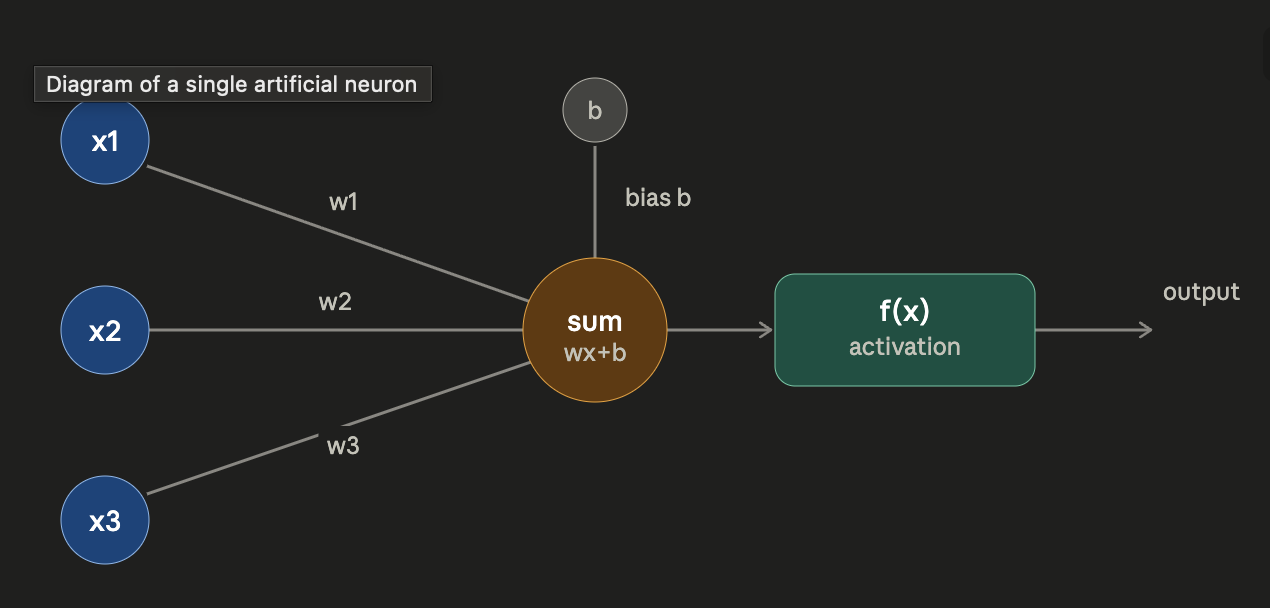

In [ ]:
#Let's manually build ONE neuron to see exactly what's happening
#before PyTorch does it for us automatically

def relu(x):
  return max(0,x)

def sigmoid(x):
  return 1 / (1 + np.exp(-x))

#A neuron receiving 3 inputs (e.g. house sqft, bedrooms, bathrooms)

x1, x2, x3 = 1200, 3, 2       #inputs
w1, w2, w3 = 0.05, 0.3, 0.2   #weights (how important each input is)
bias       = -1.5             #bias (baseline tendency to fire)

#STEP 1: weighted sum
z = (x1*w1) + (x2*w2) + (x3*w3) + bias
print(f"Weighted sum (z): {z}")

#STEP 2: apply activation function
output_relu    = relu(z)
output_sigmoid = sigmoid(z)
print(f"After ReLu:   {output_relu}")
print(f"After Sigmoid:  {output_sigmoid:.4f}")

print(f"""
This IS a multiple complete artifical neuron:
  1.Mutliply each input by its weight
  2.Sum them all, add the bias
  3.Pass through an activation function
  4.Output goes to the NEXT neuron (or is the final answer)""")

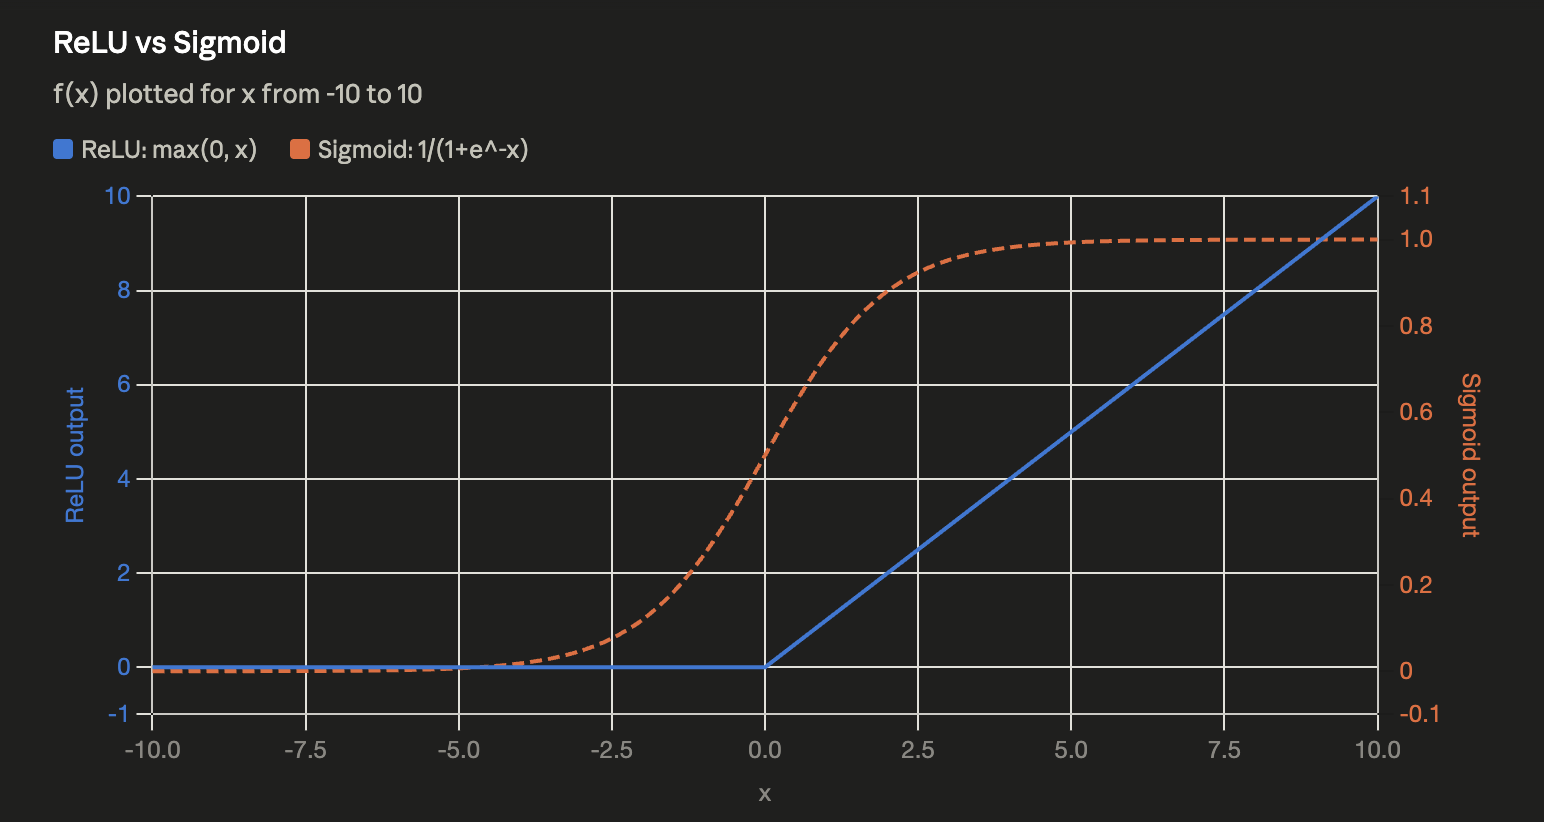

In [ ]:
import torch
import torch.nn as nn

class SimpleNN(nn.Module):
    """A basic neural network: input -> hidden -> hidden -> output"""

    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Define the LAYERS (like defining factory stations)
        self.layer1 = nn.Linear(input_size, hidden_size)   # input -> hidden1
        self.relu1 = nn.ReLU()
        self.layer2 = nn.Linear(hidden_size, hidden_size)  # hidden1 -> hidden2
        self.relu2 = nn.ReLU()
        self.layer3 = nn.Linear(hidden_size, output_size)  # hidden2 -> output

    def forward(self, x):
        # Define how data FLOWS through the layers (the assembly line)
        x = self.layer1(x)
        x = self.relu1(x)
        x = self.layer2(x)
        x = self.relu2(x)
        x = self.layer3(x)
        return x

# Create a network: 4 inputs -> 8 hidden neurons -> 8 hidden neurons -> 1 output
model = SimpleNN(input_size=4, hidden_size=8, output_size=1)
print(model)

#Count how many "weights" (parameters) this tiny network has
total_params  = sum(p.numel() for p in model.parameters())
print(f"\nTotal learnable parameters: {total_params}")
print(f"This is what TRAINING will adjust to make good predictions.")

#Look at one layer's actual weight values (randomly initialised)
print(f"\nLayer1 weights shape:  {model.layer1.weight.shape}")
print(f"Layer 1 weights (first view) : \n{model.layer1.weight[:]}")

In [ ]:
# FORWARD PASS = pushing data THROUGH the network to get a prediction
# (no training yet -- just seeing what the network currently outputs)

# Simulate one house: sqft=1200, bedrooms=3, bathrooms=2, age=5
sample_input = torch.tensor([[1200.0, 3.0, 2.0, 5.0]])
print(f"Input shape: {sample_input.shape}")  # (1, 4) = 1 sample, 4 features

prediction = model(sample_input)  # this calls .forward() automatically
print(f"Raw prediction: {prediction}")
print(f"\nThis number is currently MEANINGLESS -- the network's")
print(f"weights are still completely random. It hasn't learned anything yet!")
print(f"Tomorrow: BACKPROPAGATION teaches the network to make this number useful.")

# Process a BATCH of houses at once (this is how real training works)
batch_input = torch.tensor([
    [1200.0, 3.0, 2.0, 5.0],
    [800.0, 2.0, 1.0, 15.0],
    [2500.0, 5.0, 4.0, 2.0],
])
batch_predictions = model(batch_input)
print(f"\nBatch of 3 houses -> 3 predictions:")
print(batch_predictions)
print(f"\nProcessing many samples AT ONCE (in a batch) is dramatically")
print(f"faster than one at a time -- this is vectorization again, from Week 2!")

### Load Real MNIST Data

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# MNIST = 70,000 images of handwritten digits 0–9, 28x28 pixels each
transform = transforms.Compose([
    transforms.ToTensor(),                    # convert image to tensor
    transforms.Normalize((0.1307,), (0.3081,))  # standardize pixel values
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print(f"Training images: {len(train_dataset):,}")
print(f"Test images: {len(test_dataset):,}")

# Look at a few examples
fig, axes = plt.subplots(1, 8, figsize=(14, 2))

for i in range(8):
    img, label = train_dataset[i]
    axes[i].imshow(img.squeeze(), cmap="gray")
    axes[i].set_title(f"Label: {label}")
    axes[i].axis("off")

plt.suptitle("Sample MNIST Digits")
plt.tight_layout()
plt.show()

# DataLoader -- feeds data to the network in BATCHES during training
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Look at one batch's shape
images, labels = next(iter(train_loader))
print(f"\nOne batch shape: {images.shape}")
print("-> 64 images, 1 grayscale channel, 28x28 pixels")
print(f"Labels shape: {labels.shape}")
print("MNIST contains handwritten digits (0-9).")
print("Each image is normalized before training.")
print("DataLoader feeds data in mini-batches.")
print("Batch size = 64.")
print("Training data is shuffled.")
print("Test data is not shuffled.")
print("Each image has one corresponding label.")
print("Tensor shape = (Batch, Channel, Height, Width).")
print("Here: (64, 1, 28, 28).")
print("Ready for CNN training.")
print("-" * 40)
print("Dataset loaded successfully.")
print("Data preprocessing complete.")

###Loss Functions & Optimizers

In [ ]:
import torch.nn as nn
import torch.optim as optim

print("LOSS FUNCTIONS -- measuring 'how wrong' a prediction is")
print("=" * 55)

print("""
ANALOGY: A judge scoring how far off your guess was

CrossEntropyLoss -- for CLASSIFICATION (used for MNIST digits 0-9)
Punishes confident WRONG answers heavily.
If true answer is "7" and model says "I'm 99% sure it's a 3",
that's a HUGE loss. If model says "I'm 60% sure it's 7,
40% sure it's 1", that's a much smaller loss.

MSELoss (Mean Squared Error) -- for REGRESSION (predicting numbers)
Same MSE from Week 3's Linear Regression! Squares the error.
""")


# Build the network for MNIST
# 28 x 28 = 784 pixel inputs -> 10 digit classes

class DigitClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(784, 128)
        self.relu1 = nn.ReLU()

        self.layer2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        self.layer3 = nn.Linear(64, 10)  # 10 outputs = 10 possible digits

    def forward(self, x):

        # Flatten each 28x28 image into 784 numbers
        x = x.view(x.size(0), -1)

        x = self.relu1(self.layer1(x))
        x = self.relu2(self.layer2(x))
        x = self.layer3(x)

        return x


model = DigitClassifier().to(device)

criterion = nn.CrossEntropyLoss()  # the "judge"

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)  # the "step-taker"


print(
    f"Model created. Total parameters: "
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print("\nOPTIMIZER: Adam with learning_rate=0.001")

print(
    "This is the 'how big a step downhill' setting "
    "from our mountain analogy."
)

### The Training Loop,  Explained Line By Line

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    """One full pass through all training data = one EPOCH"""

    model.train()  # tell PyTorch we're in training mode

    total_loss = 0
    correct = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # STEP 1: FORWARD PASS
        outputs = model(images)  # get predictions

        # STEP 2: COMPUTE LOSS
        loss = criterion(outputs, labels)

        # STEP 3: BACKWARD PASS
        optimizer.zero_grad()  # reset gradients from last batch
        loss.backward()        # calculate all gradients automatically

        # STEP 4: UPDATE WEIGHTS
        optimizer.step()       # adjust every weight slightly

        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()

    avg_loss = total_loss / len(loader)
    accuracy = correct / len(loader.dataset)

    return avg_loss, accuracy


print("""
THE 4 LINES THAT MAKE UP EVERY NEURAL NETWORK TRAINING LOOP:

outputs = model(images)               # 1. FORWARD
loss = criterion(outputs, labels)     # 2. LOSS
loss.backward()                       # 3. BACKWARD (auto-gradients!)
optimizer.step()                      # 4. UPDATE

Everything else in this function is bookkeeping —
tracking loss and accuracy so we can watch progress.

loss.backward() is where the MAGIC happens — PyTorch automatically
calculates exactly how much every single one of our thousands of
weights contributed to the error, using calculus (the chain rule),
completely behind the scenes. This is called AUTOGRAD.
""")

###Train on Real MNIST Data

In [12]:
def evaluate(model, loader):

    model.eval()  # tell PyTorch we're in evaluation mode (no learning)

    correct = 0

    with torch.no_grad():  # don't waste time calculating gradients here

        for images, labels in loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            correct += (outputs.argmax(1) == labels).sum().item()

    return correct / len(loader.dataset)



print("Training DigitClassifier on MNIST...")

print("=" * 55)



history = {"train_loss": [], "train_acc": [], "test_acc": []}



for epoch in range(5):

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)

    test_acc = evaluate(model, test_loader)



    history["train_loss"].append(train_loss)

    history["train_acc"].append(train_acc)

    history["test_acc"].append(test_acc)



    print(

        f"Epoch {epoch+1}/5 | Loss: {train_loss:.4f} | "

        f"Train Acc: {train_acc:.2%} | Test Acc: {test_acc:.2%}"

    )



# THE MOST IMPORTANT CHART OF THE WEEK -- the loss curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4))



axes[0].plot(history["train_loss"], "o-", color="#00d4ff", linewidth=2)

axes[0].set_title("Training Loss Over Epochs\n(going DOWN = learning is happening!)")

axes[0].set_xlabel("Epoch")

axes[0].set_ylabel("Loss")



axes[1].plot(history["train_acc"], "o-", color="#00ff88", label="Train Accuracy")

axes[1].plot(history["test_acc"], "o-", color="#ff6b35", label="Test Accuracy")

axes[1].set_title("Accuracy Over Epochs")

axes[1].set_xlabel("Epoch")

axes[1].legend()



plt.tight_layout()

plt.show()



print(f"\nFinal test accuracy: {history['test_acc'][-1]:.2%}")

print(f"From RANDOM guessing (~10% accuracy) to {history['test_acc'][-1]:.0%}")

print(f"in just 5 epochs. THIS is backpropagation and gradient descent")

print(f"working together -- the network taught itself to read handwriting.")

Training DigitClassifier on MNIST...
Epoch 1/5 | Loss: 0.2730 | Train Acc: 91.93% | Test Acc: 95.95%
Epoch 2/5 | Loss: 0.1117 | Train Acc: 96.59% | Test Acc: 97.15%


KeyboardInterrupt: 

##Day 3

### Convulational Neural Networks (CNN) - Teaching Machines to See

#### Canadian Institute For Advanced Research, 10 classes

In [ ]:
from datasets import load_dataset
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

hf_dataset = load_dataset('uoft-cs/cifar10')

classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

class HFCifar10(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img = self.data[idx]['img']
        label = self.data[idx]['label']
        return transform(img), label


train_data = HFCifar10(hf_dataset['train'])
test_data = HFCifar10(hf_dataset['test'])

print(f'Training images {len(train_data):,}')
print(f'Test images {len(test_data):,}')

def imshow(img_tesor):
  img = img_tesor / 2 + 0.5 # undo normalization for display
  return img.permute(1,2,0).numpy()


fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i in range(8):
    img, label = train_data[i]
    axes[i].imshow(imshow(img))
    axes[i].set_title(classes[label], fontsize=9)
    axes[i].axis("off")
plt.suptitle("Sample CIFAR-10 Images (32x32 colour)")
plt.tight_layout(); plt.show()

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

images, labels = next(iter(train_loader))
print(f"Batch shape: {images.shape}")
print("-> 64 images, 3 colour channels, 32x32 pixels")

###

In [ ]:
import torch.nn.functional as F

# Manually applt a simple edge-detection filter to see the convolution in action

img,label = train_data[3]
gray_img = img.mean(dim = 0, keepdim =True).unsqueeze(0)  # Convert to grayscale

# A classic vertical edge detector filter
edge_filter = torch.tensor([[[[-1., 0., 1.],
                             [-1., 0., 1.],
                             [-1., 0., 1.]]]])

filtered = F.conv2d(gray_img, edge_filter, padding=1)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(imshow(img)); axes[0].set_title(f"Original ({classes[label]})"); axes[0].axis("off")
axes[1].imshow(gray_img.squeeze(), cmap="gray"); axes[1].set_title("Grayscale"); axes[1].axis("off")
axes[2].imshow(filtered.squeeze().detach(), cmap="gray"); axes[2].set_title("After Edge Filter"); axes[2].axis("off")
plt.tight_layout(); plt.show()

print("This ONE hand-designed filter highlights vertical edges.")
print("A real CNN has MANY filters (32, 64, 128...) per layer,")
print("and LEARNS the best filter values automatically during training.")
print("We never hand-design them like this demo.")

print(f"""
CONV2D PARAMETERS EXPLAINED:
  in_channels - how many channels come IN (3 for RGB, 1 for grayscale)
  out_channels - how many DIFFERENT filters to learn (each finds a different patterns)
  kernel_size - size of each filter (3x3 is most common)
  padding - adds a border of Zeros so output size matches input
""")

### Build a REAL CNN

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()

        # BLOCK 1: Learn simple patterns (edges, colors)
        self.conv1=nn.Conv2d(3,32,kernel_size=3,padding=1) # RGB input -> 32 filters
        self.pool1=nn.MaxPool2d(2,2) # 32x32 -> 16x16

        # BLOCK 2: Combine simple patterns into complex patterns
        self.conv2=nn.Conv2d(32,64,kernel_size=3,padding=1) # 32 -> 64 filters
        self.pool2=nn.MaxPool2d(2,2) # 16x16 -> 8x8

        self.relu=nn.ReLU()

        # FULLY CONNECTED: Make final decision
        self.fc1=nn.Linear(64*8*8,128)
        self.fc2=nn.Linear(128,num_classes)
        self.dropout=nn.Dropout(0.3)

    def forward(self,x):
        # BLOCK 1
        x=self.pool1(self.relu(self.conv1(x)))

        # BLOCK 2
        x=self.pool2(self.relu(self.conv2(x)))

        # Flatten feature maps for FC layers
        x=x.view(x.size(0),-1)

        # Classification layers
        x=self.dropout(self.relu(self.fc1(x)))
        x=self.fc2(x)

        return x

cnn_model = SimpleCNN().to(device)
print(cnn_model)

total_params = sum(p.numel() for p in cnn_model.parameters())
print(f"\nTotal parameters: {total_params:,}")

print(f"""
NOTICE THE PATTERN: CNV -> ReLu -> POOL, repeated, then FLATTEN -> FC -> OUTPUT
This is the classic CNN architecture used in almost every image
classifier, from simple demos to production systems
""")

####Train the CNN

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# Training function
def train_cnn(model, loader):
    model.train()
    total_loss, correct = 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track loss
        total_loss += loss.item()

        # Track accuracy
        correct += (outputs.argmax(1) == labels).sum().item()

    return total_loss / len(loader), correct / len(loader.dataset)


# Evaluation function
def evaluate_cnn(model, loader):
    model.eval()
    correct = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass only
            outputs = model(images)

            # Count correct predictions
            correct += (outputs.argmax(1) == labels).sum().item()

    return correct / len(loader.dataset)


print("Training CNN on CIFAR-10 (this takes a few minutes)...")

history = {
    "loss": [],
    "train_acc": [],
    "test_acc": []
}

for epoch in range(5):
    train_loss, train_acc = train_cnn(cnn_model, train_loader)

    test_acc = evaluate_cnn(cnn_model, test_loader)

    history["loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    print(f"Epoch {epoch+1}/5 | Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(history["loss"], "o-", color="#00d4ff"); axes[0].set_title("CNN Training Loss")
axes[1].plot(history["train_acc"], "o-", label="Train"); axes[1].plot(history["test_acc"],"o-",label="Test")
axes[1].set_title("CNN Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"\nFinal test accuracy: {history['test_acc'][-1]:.2%}")
print(f"CIFAR-10 is HARDER than MNIST -- real colour photos of complex")
print(f"objects vs simple handwritten digits. Even 60-70% here is solid")
print(f"progress for a small CNN trained in just 5 epochs.")

###Load Pretrained Network

In [5]:
from torchvision import models
import torch.nn as nn

# Load ResNet-18, pretrained on 14 million ImageNet images
resnet = models.resnet18(weights="IMAGENET1K_V1")

print("This network was trained by researchers on 14 MILLION images")
print("across 1000 categories -- something we could never replicate")
print("with our classroom resources. We're about to reuse that work.\n")

print(f"Original final layer: {resnet.fc}")
print("-> outputs 1000 values (one per ImageNet category)")

print("\nBut WE only have 10 categories (CIFAR-10)!")
print("We need to REPLACE this final layer with one that fits our task.")

total_params = sum(p.numel() for p in resnet.parameters())
print(f"\nTotal parameters in ResNet-18: {total_params:,}")

This network was trained by researchers on 14 MILLION images
across 1000 categories -- something we could never replicate
with our classroom resources. We're about to reuse that work.

Original final layer: Linear(in_features=512, out_features=1000, bias=True)
-> outputs 1000 values (one per ImageNet category)

But WE only have 10 categories (CIFAR-10)!
We need to REPLACE this final layer with one that fits our task.

Total parameters in ResNet-18: 11,689,512


In [8]:
import torch
import torch.nn as nn
from torchvision import models

# ---------------------------------------------------
# 1. Select GPU if available, otherwise use CPU
# ---------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---------------------------------------------------
# 2. Load a fresh pretrained ResNet-18 model
# Reloading prevents the Sequential/in_features error
# ---------------------------------------------------
resnet = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

print("\nOriginal final layer:")
print(resnet.fc)

# ---------------------------------------------------
# 3. Save the input-feature count BEFORE replacing fc
# ResNet-18's final layer normally receives 512 features
# ---------------------------------------------------
input_features = resnet.fc.in_features
print(f"\nFeatures entering the final layer: {input_features}")

# ---------------------------------------------------
# 4. Freeze all pretrained layers
# ---------------------------------------------------
for param in resnet.parameters():
    param.requires_grad = False

print("All pretrained layers have been frozen.")

# ---------------------------------------------------
# 5. Replace the original 1000-class output layer
# with a classifier for CIFAR-10
# ---------------------------------------------------
num_classes = 10

resnet.fc = nn.Sequential(
    nn.Linear(input_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
)

print("\nNew final layer:")
print(resnet.fc)

# ---------------------------------------------------
# 6. Move the model to GPU or CPU
# ---------------------------------------------------
resnet = resnet.to(device)

# ---------------------------------------------------
# 7. Count trainable and total parameters
# ---------------------------------------------------
trainable_params = sum(
    param.numel()
    for param in resnet.parameters()
    if param.requires_grad
)

total_params = sum(
    param.numel()
    for param in resnet.parameters()
)

frozen_params = total_params - trainable_params

print("\nParameter summary:")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {frozen_params:,}")
print(f"Total parameters:     {total_params:,}")
print(f"Percentage trained:   {trainable_params / total_params:.1%}")
print(f"Percentage frozen:    {frozen_params / total_params:.1%}")

# ---------------------------------------------------
# 8. Loss function and optimizer
# Only trainable parameters are sent to the optimizer
# ---------------------------------------------------
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda param: param.requires_grad, resnet.parameters()),
    lr=0.001
)

print("\nModel setup completed successfully.")

Using device: cpu

Original final layer:
Linear(in_features=512, out_features=1000, bias=True)

Features entering the final layer: 512
All pretrained layers have been frozen.

New final layer:
Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=10, bias=True)
)

Parameter summary:
Trainable parameters: 133,898
Frozen parameters:    11,176,512
Total parameters:     11,310,410
Percentage trained:   1.2%
Percentage frozen:    98.8%

Model setup completed successfully.


###Fine tune CIFAR-10

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader, Subset

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load ResNet-18, pretrained on ImageNet
resnet = models.resnet18(weights="IMAGENET1K_V1")

print("This network was trained by researchers on 14 MILLION images")
print("across 1000 categories -- something we could never replicate")
print("with our classroom resources. We're about to reuse that work.\n")

print(f"Original final layer: {resnet.fc}")
print("-> outputs 1000 values (one per ImageNet category)")

print("\nBut WE only have 10 categories (CIFAR-10)!")
print("We need to REPLACE this final layer with one that fits our task.")


# Count total parameters
total_params = sum(p.numel() for p in resnet.parameters())
print(f"\nTotal parameters in ResNet-18: {total_params:,}")


# STEP 1: FREEZE all existing layers -- "don't change what you already know"
for param in resnet.parameters():
    param.requires_grad = False

print("All layers frozen. None of the pretrained knowledge will be lost.")


# STEP 2: REPLACE the final layer for OUR specific task (10 classes)
num_classes = 10

resnet.fc = nn.Sequential(
    nn.Linear(resnet.fc.in_features,256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256,num_classes)
)


# NOTE: New layers created this way have requires_grad=True by default!


resnet = resnet.to(device)


# Verify: how much of the network will ACTUALLY be trained?
trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet.parameters())

print(f"Trainable parameters: {trainable:,}")
print(f"Total parameters: {total:,}")
print(f"Percentage being trained: {trainable/total:.1%}")


# ResNet expects 224x224 images - CIFAR is 32x32, so we resize
transform_resnet = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])


# Load CIFAR-10 dataset
train_data_r = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform_resnet
)

test_data_r = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform_resnet
)


# Use a SMALL subset for speed in class -- transfer learning needs
# far less data than training from scratch!

train_subset = Subset(train_data_r,range(2000))
test_subset = Subset(test_data_r,range(500))


train_loader_r = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True
)

test_loader_r = DataLoader(
    test_subset,
    batch_size=32,
    shuffle=False
)


# Loss function
criterion = nn.CrossEntropyLoss()


# Only optimise the parameters that require_grad=True (our new layers)
optimizer = optim.Adam(
    filter(lambda p:p.requires_grad,resnet.parameters()),
    lr=0.001
)


print(f"Fine-tuning on just {len(train_subset)} images (vs 50,000 from scratch)")
print("-"*55)


# TRAINING LOOP
for epoch in range(3):

    resnet.train()

    total_loss = 0
    correct = 0


    for images, labels in train_loader_r:

        images, labels = images.to(device), labels.to(device)


        # Forward pass
        outputs = resnet(images)


        # Calculate loss
        loss = criterion(outputs,labels)


        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        # Track loss and accuracy
        total_loss += loss.item()
        correct += (outputs.argmax(1)==labels).sum().item()



    # Evaluation
    resnet.eval()

    test_correct = 0


    with torch.no_grad():

        for images, labels in test_loader_r:

            images, labels = images.to(device), labels.to(device)


            outputs = resnet(images)


            test_correct += (outputs.argmax(1)==labels).sum().item()



    print(
        f"Epoch {epoch+1}/3 | "
        f"Loss: {total_loss/len(train_loader_r):.4f} | "
        f"Train Acc: {correct/len(train_subset):.2%} | "
        f"Test Acc: {test_correct/len(test_subset):.2%}"
    )


print("\nWith only 2,000 training images and 3 epochs, transfer learning")
print("often matches or beats a CNN trained from scratch.")


This network was trained by researchers on 14 MILLION images
across 1000 categories -- something we could never replicate
with our classroom resources. We're about to reuse that work.

Original final layer: Linear(in_features=512, out_features=1000, bias=True)
-> outputs 1000 values (one per ImageNet category)

But WE only have 10 categories (CIFAR-10)!
We need to REPLACE this final layer with one that fits our task.

Total parameters in ResNet-18: 11,689,512
All layers frozen. None of the pretrained knowledge will be lost.
Trainable parameters: 133,898
Total parameters: 11,310,410
Percentage being trained: 1.2%


  0%|          | 623k/170M [00:06<30:16, 93.5kB/s]


KeyboardInterrupt: 

In [15]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

hf_dataset  = load_dataset("uoft-cs/cifar10")

classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

class HFCifar10(Dataset):
  def __init__(self, hf_split):
    self.data = hf_split
  def __len__(self):
    return len(self.data)
  def __getitem__(self, idx):
    img = self.data[idx]["img"]
    label = self.data[idx]["label"]
    return transform(img), label

train_data_r = HFCifar10(hf_dataset["train"])
test_data_r = HFCifar10(hf_dataset["test"])

# ResNet expects 224x224 images - CIFAR is 32x32, so we resize
transform_resnet = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])

# train_data_r = datasets.CIFAR10(root="./data",train=True,download=True,transform=transform_resnet)
# test_data_r = datasets.CIFAR10(root="./data",train=False,download=True,transform=transform_resnet)

# Use a SMALL subset for speed in class -- transfer learning needs
# far less data than training from scratch!

from torch.utils.data import Subset

train_subset = Subset(train_data_r,range(5000)) # only 2000 images!
test_subset = Subset(test_data_r,range(500))

train_loader_r = DataLoader(train_subset,batch_size=32,shuffle=True)
test_loader_r = DataLoader(test_subset,batch_size=32,shuffle=False)

criterion = nn.CrossEntropyLoss()

# Only optimise the parameters that require_grad=True (our new layers)
optimizer = optim.Adam(filter(lambda p:p.requires_grad,resnet.parameters()),lr=0.001)

print(f"Fine-tuning on just {len(train_subset)} images (vs 50,000 from scratch)")
print("="*55)

for epoch in range(3):
  resnet.train()
  total_loss, correct = 0, 0
  for images, labels in train_loader_r:
    images, labels = images.to(device), labels.to(device)
    outputs = resnet(images)
    loss = criterion(outputs,labels)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    total_loss += loss.item()
    correct += (outputs.argmax(1) == labels).sum().item()

  resnet.eval()
  test_correct = 0
  with torch.no_grad():
    for images, labels in test_loader_r:
      images, labels = images.to(device), labels.to(device)
      test_correct += (resnet(images).argmax(1)==labels).sum().item()

  print(f"Epoch {epoch+1}/3 | Loss: {total_loss/len(train_loader_r):.4f} | "
        f"Train Acc: {correct/len(train_subset):.2%} | "
        f"Test Acc: {test_correct/len(test_subset):.2%}")

print(f"\nWith only 2,000 training images and 3 epochs, transfer learning")
print(f"often matches or beats yesterday's from scratch CNN trained on")
print(f"the FULL 50,000 images for 5 epochs. That's the power of reuse.")

Fine-tuning on just 5000 images (vs 50,000 from scratch)
Epoch 1/3 | Loss: 2.0292 | Train Acc: 29.04% | Test Acc: 36.20%
Epoch 2/3 | Loss: 1.7871 | Train Acc: 37.58% | Test Acc: 41.20%
Epoch 3/3 | Loss: 1.7088 | Train Acc: 39.46% | Test Acc: 41.00%

With only 2,000 training images and 3 epochs, transfer learning
often matches or beats yesterday's from scratch CNN trained on
the FULL 50,000 images for 5 epochs. That's the power of reuse.
